# Portfolio Project 2

### Project Links

**GitHub repository:**  
https://github.com/simoneviktoriaeide/IND320_Simone_Eide

**Streamlit application:**  
https://reservoir-insights-norway-simoneeide.streamlit.app/


<div style="background-color: #eaf3fa; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">AI Usage</h3>

<p>
I used ChatGPT quite extensively during Project 2, as I encountered many technical challenges throughout the assignment. AI was particularly helpful when working with the ENTSO-E API, which I found to be the most difficult part of the project. I used it to understand the API, troubleshoot error messages, and develop and adjust the code for retrieving and processing electricity flow data.
</p>

<p>
I also used ChatGPT for guidance when setting up Spark and Cassandra, working with MongoDB, and updating my Streamlit application. It helped me understand how the different tools connect and suggested solutions when my code did not work as expected.
</p>

<p>
AI was used for explanations, debugging, and generating or modifying parts of the code. I tested the suggested solutions in my own environment and made adjustments along the way. Although I relied on AI quite a lot, I tried to understand what the code was doing rather than simply copying it.
</p>

<p>
Overall, AI played an important role in helping me complete the technical parts of this project, especially when I encountered problems that I struggled to solve independently.
</p>

</div>



<div style="background-color: #96c8ee; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">Log of Activities</h3>

<p>
In Project 2, I continued working with the tools and methods introduced in the course, but this time with a greater focus on APIs, databases, and data processing. My goal was to retrieve data from external sources, process it using Spark, store it in databases, and eventually use it in my Streamlit application.
</p>

<p>
I started by setting up the environment and connecting Spark to Cassandra. This was challenging because several different tools had to work together, and it was sometimes difficult to understand whether an error came from Python, Spark, Java, or Cassandra. After getting the connection to work, I moved on to the NVE API. I replaced the CSV-based approach from Project 1 with direct API requests and used the reservoir data to recreate the visualizations.
</p>

<p>
The next step was working with the ENTSO-E API, which was definitely the most difficult part of the project. I struggled both with understanding how to retrieve the correct electricity flow data and with errors that appeared while writing and running the code. There were several things I had to adjust before the data could be processed properly. Once I had retrieved the data, I cleaned it, worked with it in Spark, and stored it in Cassandra. I then read the data back and created visualizations of electricity imports and exports.
</p>

<p>
Finally, I transferred the processed data to MongoDB and used it to build a new page in my Streamlit application. Connecting the different parts and making the interactive controls work was also challenging.
</p>

<p>
Overall, this project took more time than I expected. Although I still find many of the tools difficult, I have gained a better understanding of how APIs, data processing, databases, and visualizations can work together in one project.
</p>

</div>


## 0. Importing Necessary Libraries

In [ ]:
# Standard Python libraries
# Used for file paths, environment settings, dates, and XML data
import os
import sys
from pathlib import Path
from datetime import datetime, timezone, time
from urllib.parse import quote_plus
import xml.etree.ElementTree as ET


# Data retrieval and processing
# Used to retrieve API data and work with DataFrames
import requests
import pandas as pd
from dateutil.relativedelta import relativedelta


# Apache Spark
# Used for distributed data processing and Cassandra integration
from pyspark.sql import SparkSession
from pyspark.sql import functions as F


# MongoDB
# Used to connect to MongoDB Atlas and insert processed data
import pymongo
from pymongo import MongoClient, ReplaceOne
from pymongo.server_api import ServerApi


# Data visualization
# Used to create line plots and pie charts
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

## 1. Setting up Apache Spark and Cassandra 

In this section I configure Apache Spark and test the connection to Apache Cassandra running in Docker.

### 1.1 Configuring the environment

Before starting Spark, I set the `HADOOP_HOME` environment variable to the location of Hadoop on my Windows computer.

This allows Spark to find the required Windows utilities (`winutils.exe`). I also import `SparkSession` from PySpark, which I will use to start Spark.

In [ ]:
os.environ["HADOOP_HOME"] = "C:/Users/Simone/hadoop-3.3.1"  # Sets the location of my hadoop folder
os.environ["PATH"] = os.environ["HADOOP_HOME"] + "/bin;" + os.environ["PATH"] # Adds hadoops bin folder to PATH

print("HADOOP_HOME:", os.environ["HADOOP_HOME"])
print("winutils finnes:", os.path.isfile(
    os.path.join(os.environ["HADOOP_HOME"], "bin", "winutils.exe")
))

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

HADOOP_HOME: C:/Users/Simone/hadoop-3.3.1
winutils finnes: True


In [ ]:
# Set the location of Java 17
os.environ["JAVA_HOME"] = r"C:\Users\Simone\anaconda3\envs\ind320\Library"

# Set the location of Hadoop
os.environ["HADOOP_HOME"] = "C:/Users/Simone/hadoop-3.3.1"

# Add Java and Hadoop to PATH
os.environ["PATH"] = (
    os.path.join(os.environ["JAVA_HOME"], "bin")
    + os.pathsep
    + os.path.join(os.environ["HADOOP_HOME"], "bin")
    + os.pathsep
    + os.environ["PATH"]
)

# Use the same Python environment for Jupyter and Spark
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Check the configuration
print("Python:", sys.version)
print("JAVA_HOME:", os.environ["JAVA_HOME"])
print("HADOOP_HOME:", os.environ["HADOOP_HOME"])
print("winutils exists:", os.path.isfile(
    os.path.join(os.environ["HADOOP_HOME"], "bin", "winutils.exe")
))

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
JAVA_HOME: C:\Users\Simone\anaconda3\envs\ind320\Library
HADOOP_HOME: C:/Users/Simone/hadoop-3.3.1
winutils exists: True


### 1.2 Starting Apache Spark

I create a SparkSession using PySpark, which allows me to process data with Apache Spark.

I load the Spark Cassandra Connector so that Spark can communicate with my Cassandra database running in Docker.

I also configure Spark to use a limited amount of memory because Im running it locally on my computer.

In [5]:
spark = (
    SparkSession.builder
    .master("local[1]") # Tells how and where to run spark: Using one thread and running locally on my computer  
    .appName("IND320_Cassandra_Test") # Gives my spark application a name
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1") # Loads the connector that allows Spark to communicate with Cassandra
    .config("spark.cassandra.connection.host", "127.0.0.1") # Specifies the address of Cassandra running on my computer
    .config("spark.cassandra.connection.port", "9042") # Specifies the port used to connect to Cassandra
    .config("spark.driver.memory", "512m") # Sets the Spark driver memory to 512 MB
    .config("spark.ui.enabled", "false") # Disables the Spark web interface (for the test because of limited memory)
    .config("spark.python.worker.reuse", "false")
    .getOrCreate() # Gets an existing SparkSession or creates a new one
)

print("Spark startet!")

Spark startet!


In [6]:
# Test communication between Python and Spark
spark.createDataFrame(
    [(1, "test")],
    ["id", "name"]
).show()

+---+----+
| id|name|
+---+----+
|  1|test|
+---+----+



### 1.3 Testing the connection between Spark and Cassandra

In [7]:

df = (
    spark.read
    .format("org.apache.spark.sql.cassandra") # Tells Spark to read data from Cassandra
    .options(table="spark_test", keyspace="ind320_test") # Starts reading data using Spark
    .load() # Creates a Spark DataFrame from the Cassandra table
)

df.show() # Display table (testing purposes)

+---+----+
| id|navn|
+---+----+
+---+----+



## 2. Retrieving and Investigating Reservoir Data from the NVE API

In this section, I will retrieve Norwegian reservoir statistics directly from the NVE API instead of using the CSV file from Project 1. This will allow my dashboard to use data from an external sourcE

In [2]:
# Retrieve reservoir areas from the NVE API

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

response = requests.get(url, timeout=15)

print("Status code:", response.status_code)

Status code: 200


In [3]:
# Convert the API response to Python data
areas = response.json()

print(type(areas))
print(areas)

<class 'list'>
[{'land': [{'navn': 'Norge', 'navn_langt': 'Norge', 'beskrivelse': 'Hele landet', 'omrType': 'NO', 'omrnr': 0}], 'elspot': [{'navn': 'NO 1', 'navn_langt': 'Elspotområde 1', 'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).', 'omrType': 'EL', 'omrnr': 1}, {'navn': 'NO 2', 'navn_langt': 'Elspotområde 2', 'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.', 'omrType': 'EL', 'omrnr': 2}, {'navn': 'NO 3', 'navn_langt': 'Elspotområde 3', 'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.', 'omrType': 'EL', 'omrnr': 3}, {'navn': 'NO 4', 'navn_langt': 'Elspotområde 4', 'beskrivelse': 'Nord-Norge. Omfatter resten av Trøndelag og Nord-Norge.', 'omrType': 'EL', 'omrnr': 4}, {'navn': '

In [4]:
# Extract electricity price areas from the API response
elspot_areas = areas[0]["elspot"]

for area in elspot_areas:
    print(area["navn"])

NO 1
NO 2
NO 3
NO 4
NO 5


In [5]:
# Extract electricity price areas from the API response
vassdrag_areas = areas[0]["vassdrag"]

for area in vassdrag_areas:
    print(area["navn"])

VASS1
VASS2
VASS3
VASS4



The API lists 4 VASS areas, while the CSV from Project-part 1 only contains 3. Why is VASS4 missing from the CSV?

In [6]:
# Retrieve reservoir statistics from the NVE API
url_data = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response_data = requests.get(url_data, timeout=30) # Names the response response_data and retrieves the data

print("Status code:", response_data.status_code) 

Status code: 200


In [7]:
# Convert the API response to Python data
reservoir_data = response_data.json()

print(type(reservoir_data)) # Printing type
print(len(reservoir_data))  # Printing the length (size) of the data

<class 'list'>
14922


In [8]:
# Inspect the first reservoir data record
print(reservoir_data[0])

{'dato_Id': '1995-09-03', 'omrType': 'EL', 'omrnr': 4, 'iso_aar': 1995, 'iso_uke': 35, 'fyllingsgrad': 0.94472134, 'kapasitet_TWh': 21.079208, 'fylling_TWh': 19.913979, 'neste_Publiseringsdato': '0001-01-01T00:00:00', 'fyllingsgrad_forrige_uke': 0.9368882, 'endring_fyllingsgrad': 0.007833123}


In [9]:
# Convert reservoir data into a pandas DataFrame
df_reservoir = pd.DataFrame(reservoir_data)

df_reservoir.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [10]:
# Inspect the data types
df_reservoir.dtypes

dato_Id                         str
omrType                         str
omrnr                         int64
iso_aar                       int64
iso_uke                       int64
fyllingsgrad                float64
kapasitet_TWh               float64
fylling_TWh                 float64
neste_Publiseringsdato          str
fyllingsgrad_forrige_uke    float64
endring_fyllingsgrad        float64
dtype: object

## 3. Preparing the NVE data for Analysis

The API data looks very similar to the CSV file used in project part 1. Therefore, much of the data preprocessing will be the same. In this section, I prepare the reservoir data for further analysis and visualization. I will convert the date column to a datetime format and sort the data chronologically. Since the dataset contains multiple geographical areas, I will also make sure that records from different areas are handled correctly.

In [11]:
# Convert the date column to datetime
df_reservoir["dato_Id"] = pd.to_datetime(df_reservoir["dato_Id"])

# Check the new data type
print(df_reservoir["dato_Id"].dtype)

datetime64[us]


In [12]:
# Sort reservoir data chronologically
df_reservoir = df_reservoir.sort_values(by="dato_Id")

# Display the first five rows
df_reservoir.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
11344,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
11170,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14499,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
9678,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


In [13]:
# Find the unique area combinations in the reservoir data
df_reservoir[["omrType", "omrnr"]].drop_duplicates().sort_values(["omrType", "omrnr"])

,omrType,omrnr
7882,EL,1
7282,EL,2
4579,EL,3
3014,EL,4
3111,EL,5
9678,NO,0
14499,VASS,1
11344,VASS,2
11170,VASS,3


In [14]:
# Count the number of records for each date
records_per_date = df_reservoir.groupby("dato_Id").size()

# Check how many dates have each number of records
records_per_date.value_counts().sort_index()

9    1658
Name: count, dtype: int64

In [15]:
# Create an area identifier by combining area type and number
df_reservoir["area"] = (
    df_reservoir["omrType"] + df_reservoir["omrnr"].astype(str)
)

# Display the first five rows
df_reservoir[["dato_Id", "area", "fyllingsgrad"]].head()

,dato_Id,area,fyllingsgrad
3111,1995-01-08,EL5,0.616448
11344,1995-01-08,VASS2,0.608856
11170,1995-01-08,VASS3,0.566906
14499,1995-01-08,VASS1,0.635440
9678,1995-01-08,NO0,0.607988


## 4. Recreating Reservoir Plots Using NVE API Data (reused code from Project_1.ipynb)

I recreated the reservoir plots from Project 1 using data retrieved directly from the NVE API. I converted the API response into a pandas DataFrame and applied the same preprocessing steps as in Project 1.

The plots now use API data instead of the local CSV file.

### 4.1 Norwegian to English names + checking that the dataframe matches the one in Project_1.ipynb

In [16]:
df = df_reservoir.copy()  # Creates a working copy of the NVE API dataset

In [17]:
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_fill_level",
    "endring_fyllingsgrad": "fill_level_change"
})  # Renames columns to clear and consistent English names

In [18]:
print(df["date"].is_monotonic_increasing)  # Checks if dates are sorted chronologically

True


### 4.2 Fill_level for all three area-types

<Axes: title={'center': 'Reservoir fill level - EL areas'}, xlabel='Date', ylabel='Fill level'>

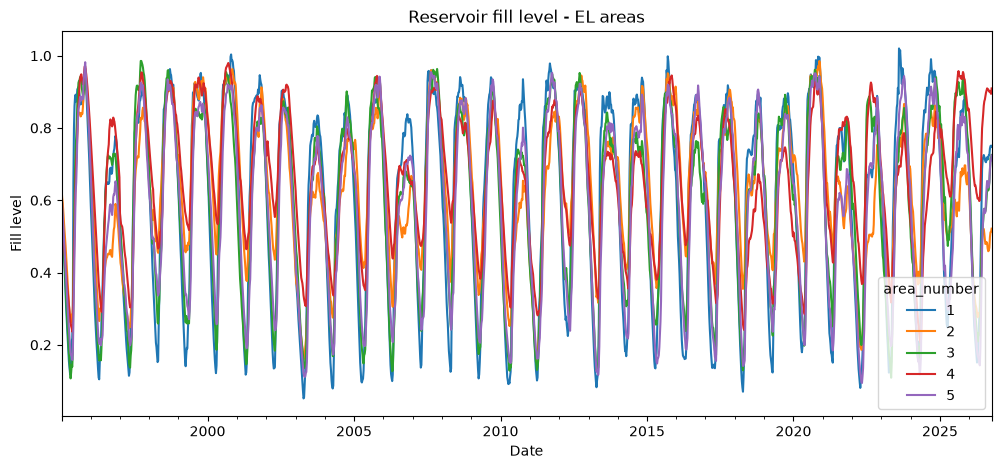

In [19]:
el_df = df[df["area_type"] == "EL"].copy()  # Selects all EL areas

el_pivot = el_df.pivot(
    index="date",
    columns="area_number",
    values="fill_level"
)  # Creates one column per EL area

el_pivot.plot(
    figsize=(12, 5),
    title="Reservoir fill level - EL areas",
    xlabel="Date",
    ylabel="Fill level"
)

<Axes: title={'center': 'Reservoir fill level - VASS areas'}, xlabel='Date', ylabel='Fill level'>

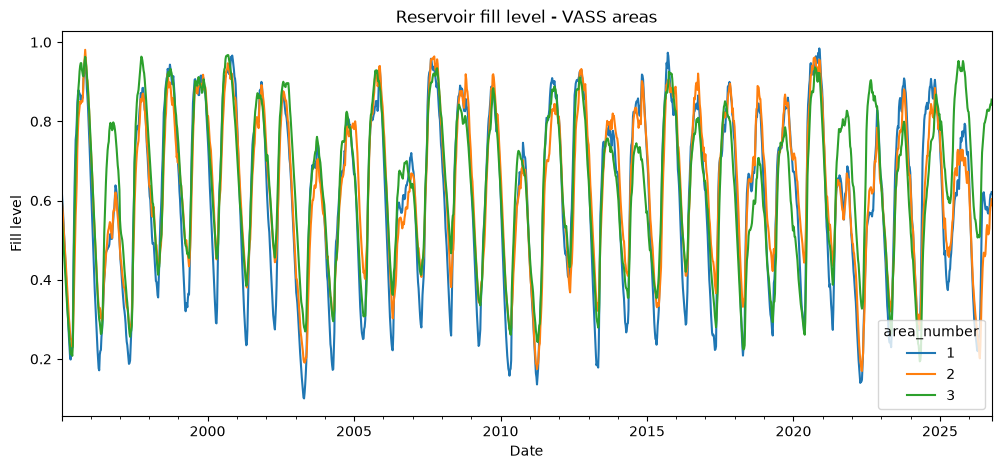

In [20]:
vass_df = df[df["area_type"] == "VASS"].copy()  # Selects all VASS areas

vass_pivot = vass_df.pivot(
    index="date",
    columns="area_number",
    values="fill_level"
)  # Creates one column per VASS area

vass_pivot.plot(
    figsize=(12, 5),
    title="Reservoir fill level - VASS areas",
    xlabel="Date",
    ylabel="Fill level"
)

<Axes: title={'center': 'Reservoir fill level - NO'}, xlabel='Date', ylabel='Fill level'>

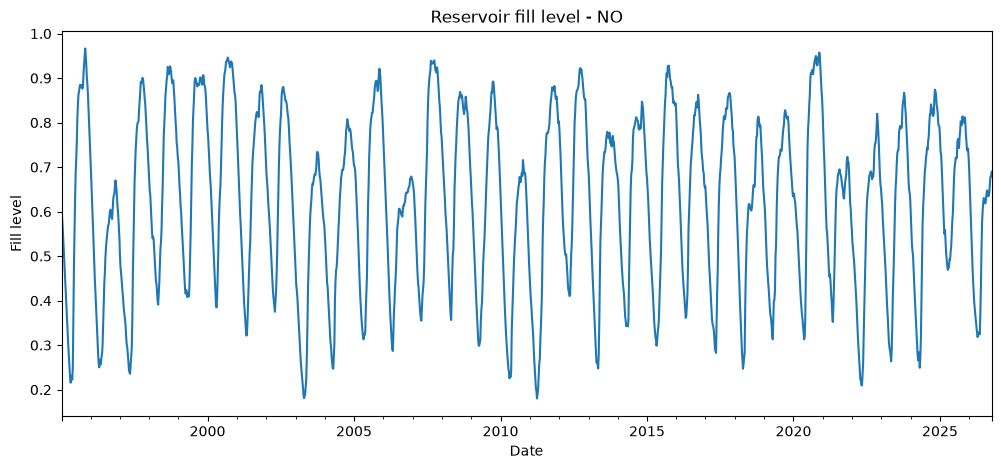

In [21]:
no_df = df[df["area_type"] == "NO"].copy()  # Selects all NO observations

no_df.plot(
    x="date",
    y="fill_level",
    figsize=(12, 5),
    title="Reservoir fill level - NO",
    xlabel="Date",
    ylabel="Fill level",
    legend=False
)

### 4.3 Capacity_twh plot for all area_types

<Axes: title={'center': 'Reservoir capacity by area'}, xlabel='Area', ylabel='Capacity (TWh)'>

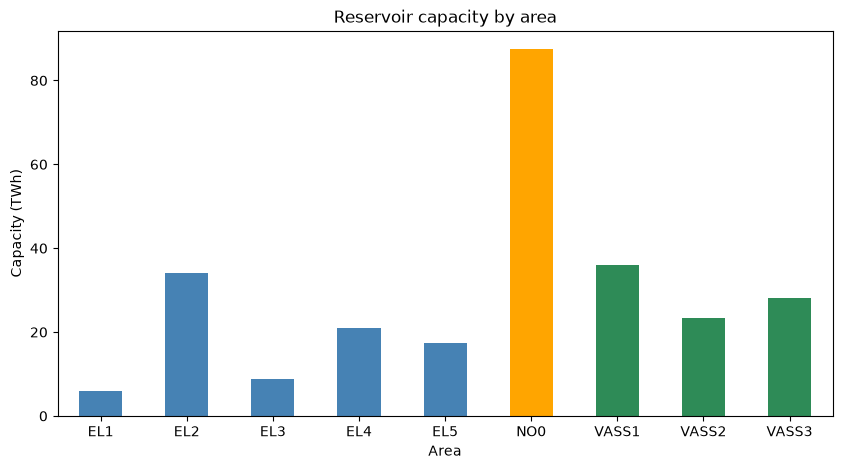

In [22]:
# Selects one capacity value for each area since it is constant
capacity = (
    df.groupby(["area_type", "area_number"])["capacity_twh"]
    .first()
    .reset_index()
)

# Creates labels such as EL1, NO0 and VASS1
capacity["area"] = (
    capacity["area_type"] + capacity["area_number"].astype(str)
)

# Assigns one color to each area type
colors = capacity["area_type"].map({
    "EL": "steelblue",
    "NO": "orange",
    "VASS": "seagreen"
})

# Compares reservoir capacity across all areas
capacity.plot(
    x="area",
    y="capacity_twh",
    kind="bar",
    color=colors,
    figsize=(10, 5),
    title="Reservoir capacity by area",
    xlabel="Area",
    ylabel="Capacity (TWh)",
    legend=False,
    rot=0
)

### 4.4 Stored_energy_twh

<Axes: title={'center': 'Stored energy – EL areas'}, xlabel='Date', ylabel='Stored energy (TWh)'>

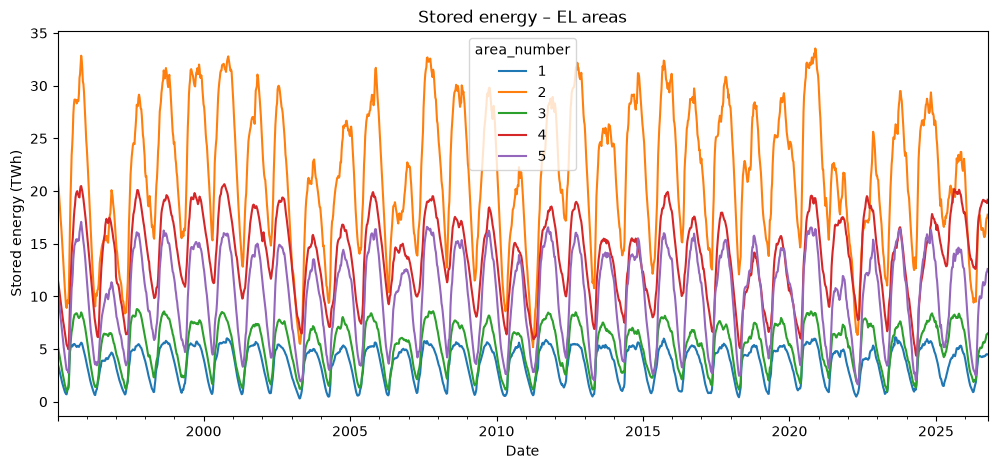

In [23]:

# Creates one stored energy column per EL area
el_energy = el_df.pivot(
    index="date",
    columns="area_number",
    values="stored_energy_twh"
)

# Plots stored energy over time for all five EL areas
el_energy.plot(
    figsize=(12, 5),
    title="Stored energy – EL areas",
    xlabel="Date",
    ylabel="Stored energy (TWh)"
)

<Axes: title={'center': 'Stored energy - VASS areas'}, xlabel='Date', ylabel='Stored energy (TWh)'>

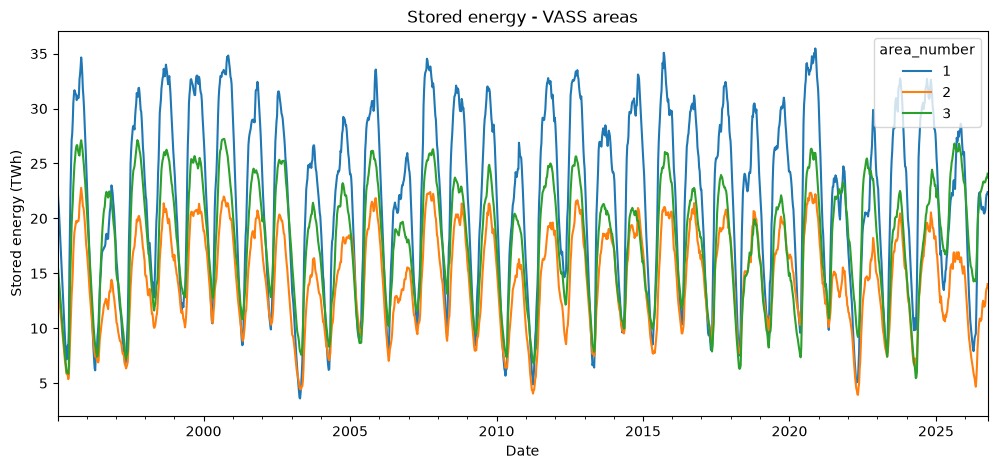

In [24]:
# Creates one stored energy column per VASS area
vass_energy = vass_df.pivot(
    index="date",
    columns="area_number",
    values="stored_energy_twh"
)

# Plots stored energy over time for all three VASS areas
vass_energy.plot(
    figsize=(12, 5),
    title="Stored energy - VASS areas",
    xlabel="Date",
    ylabel="Stored energy (TWh)"
)

<Axes: title={'center': 'Stored energy - NO'}, xlabel='Date', ylabel='Stored energy (TWh)'>

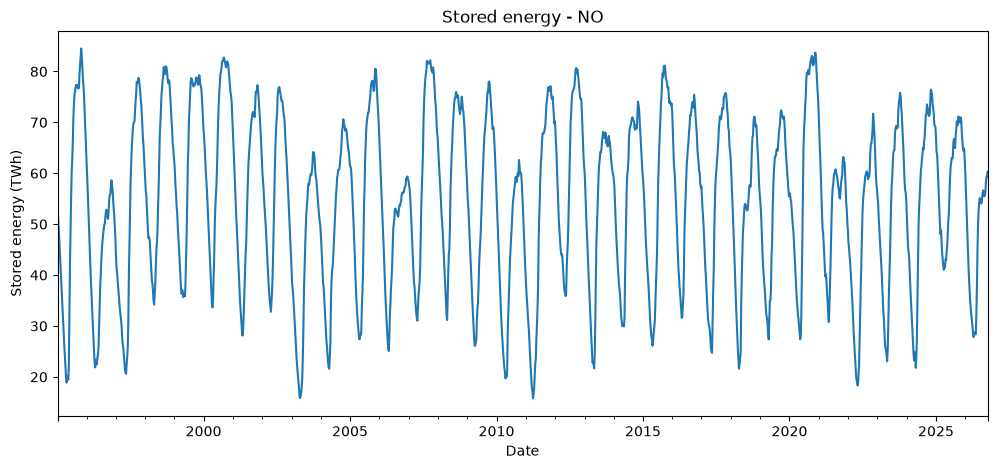

In [25]:
# Plots stored energy over time for NO
no_df.plot(
    x="date",
    y="stored_energy_twh",
    figsize=(12, 5),
    title="Stored energy - NO",
    xlabel="Date",
    ylabel="Stored energy (TWh)",
    legend=False
)

### 4.5 fill_level_change

<Axes: title={'center': 'Change in fill level - EL areas'}, xlabel='Date', ylabel='Change in fill level'>

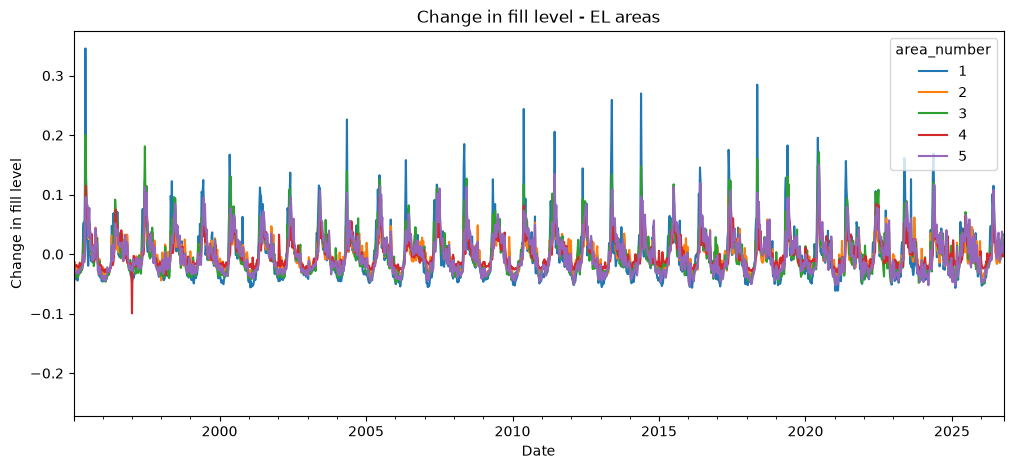

In [26]:
# Creates one fill level change column per EL area
el_fill_change = el_df.pivot(
    index="date",
    columns="area_number",
    values="fill_level_change"
)

# Plots the weekly change for all EL areas
el_fill_change.plot(
    figsize=(12, 5),
    title="Change in fill level - EL areas",
    xlabel="Date",
    ylabel="Change in fill level"
)

<Axes: title={'center': 'Change in fill level - VASS areas'}, xlabel='Date', ylabel='Change in fill level'>

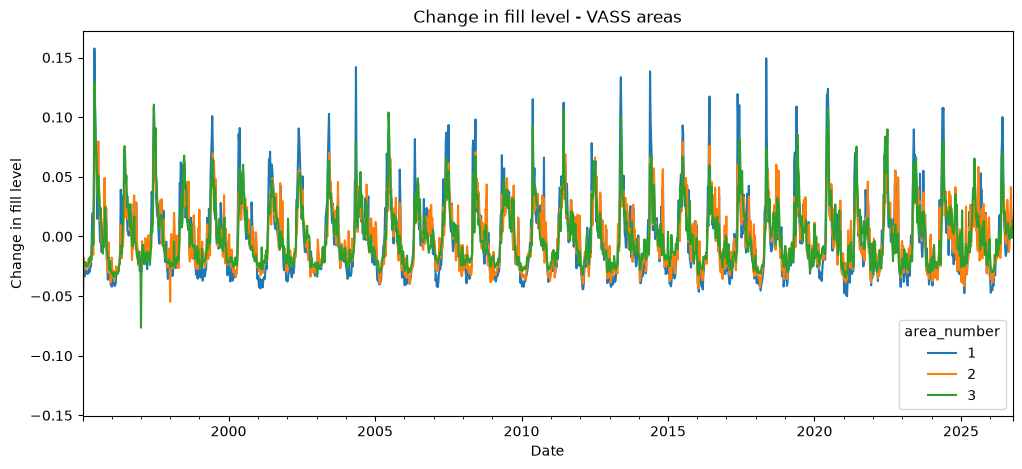

In [27]:
# Creates one fill level change column per VASS area
vass_fill_change = vass_df.pivot(
    index="date",
    columns="area_number",
    values="fill_level_change"
)

# Plots the weekly change for all VASS areas
vass_fill_change.plot(
    figsize=(12, 5),
    title="Change in fill level - VASS areas",
    xlabel="Date",
    ylabel="Change in fill level"
)

<Axes: title={'center': 'Change in fill level - NO'}, xlabel='Date', ylabel='Change in fill level'>

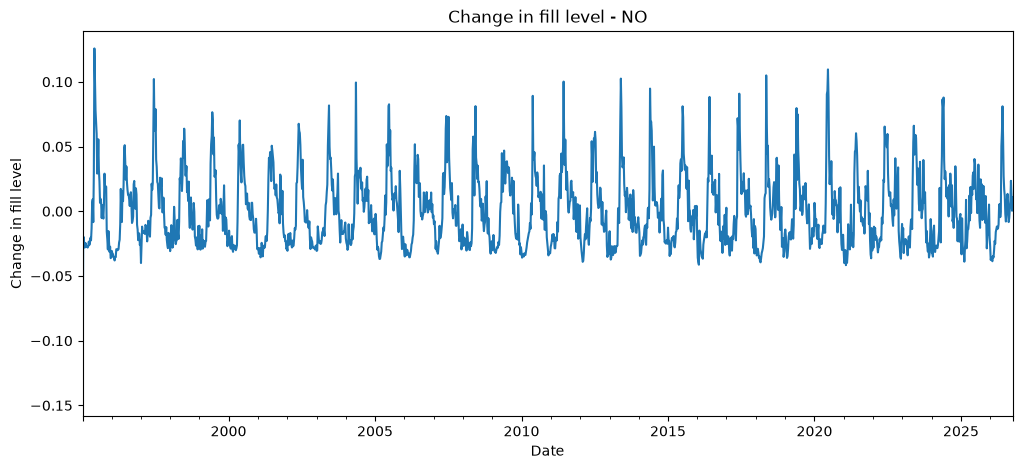

In [28]:
# Plots the weekly change in fill level for NO
no_df.plot(
    x="date",
    y="fill_level_change",
    figsize=(12, 5),
    title="Change in fill level - NO",
    xlabel="Date",
    ylabel="Change in fill level",
    legend=False
)

### 4.6 Plotting combined columns

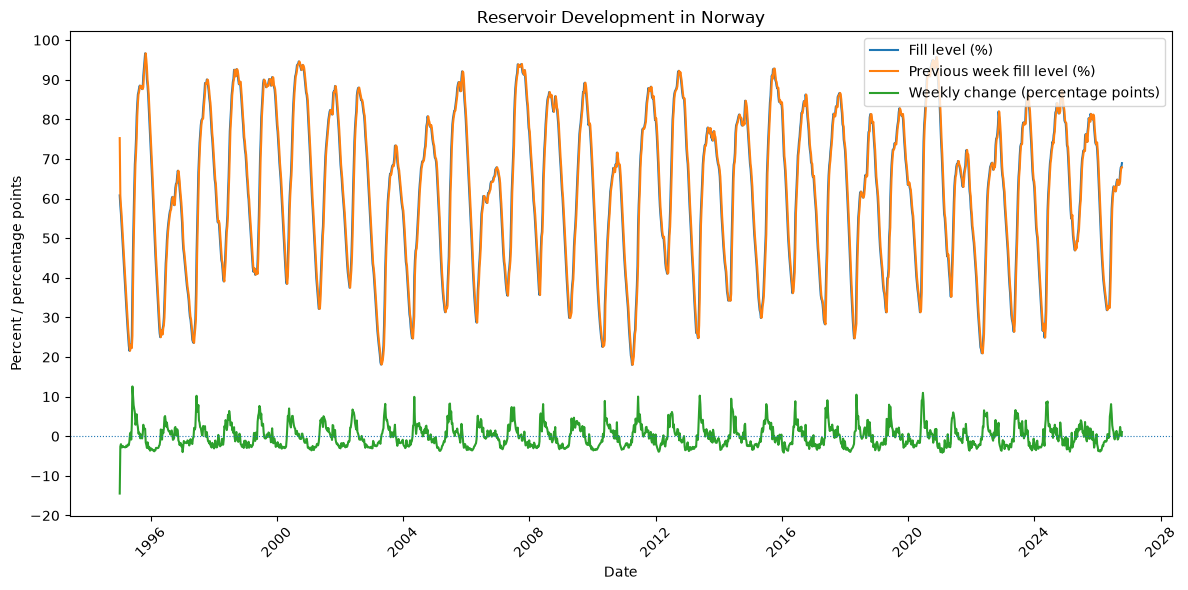

In [29]:
# Select national reservoir data
no_data = df[df["area_type"] == "NO"].copy()
no_data = no_data.sort_values("date")

# Convert reservoir levels to percent and weekly change to percentage points
fill_level = no_data["fill_level"] * 100
previous_week = no_data["previous_week_fill_level"] * 100
weekly_change = no_data["fill_level_change"] * 100

# Create the combined plot
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    no_data["date"],
    fill_level,
    label="Fill level (%)"
)

ax.plot(
    no_data["date"],
    previous_week,
    label="Previous week fill level (%)"
)

ax.plot(
    no_data["date"],
    weekly_change,
    label="Weekly change (percentage points)"
)

# Add a reference line at zero for weekly change
ax.axhline(
    y=0,
    linewidth=0.8,
    linestyle=":"
)

ax.set_title("Reservoir Development in Norway")
ax.set_xlabel("Date")
ax.set_ylabel("Percent / percentage points")

ax.legend()
ax.yaxis.set_major_locator(MultipleLocator(10))

plt.xticks(rotation=45)
fig.tight_layout()

plt.show()

## 5. MongoDB Atlas Setup and Connection

In this section, I connect to MongoDB Atlas using PyMongo.
I load my credentials from a local file and verify the connection using a ping command.

In [ ]:
# Find the MongoDB credentials file
credentials_path = Path("../../No_sync/MongoDB.txt")

print("Current working directory:", Path.cwd())
print("Credentials file found:", credentials_path.is_file())

Current working directory: c:\Users\Simone\Portfolio_IND320\IND320_Simone_Eide\notebooks
Credentials file found: True


In [26]:
# Read MongoDB credentials from the local file
credentials = credentials_path.read_text().splitlines()

print("Two credential lines found:", len(credentials) == 2)

Two credential lines found: True


In [ ]:
print("PyMongo version:", pymongo.version)

PyMongo version: 4.19.0


In [28]:


# Read credentials from the local file
username, password = credentials_path.read_text().splitlines()

# Using the hostname from the MongoDB Atlas connection string
host = "ind320.0zlleiy.mongodb.net"

# Build the connection string
uri = f"mongodb+srv://{quote_plus(username)}:{quote_plus(password)}@{host}/?retryWrites=true&w=majority"

# Connecting to MongoDB Atlas
client = MongoClient(uri, server_api=ServerApi("1"), serverSelectionTimeoutMS=10000)

# Testing the connection
try:
    client.admin.command("ping")
    print("Successfully connected to MongoDB!")
except Exception as e:
    print("Connection failed:", type(e).__name__)

Successfully connected to MongoDB!


## 6. ENTSOE API

### 6.1 Connecting to ENTSOE API

In [ ]:
# Read the ENTSO-E API token from a local file
token_path = Path("../../No_sync/ENTSOE_token.txt")
token = token_path.read_text(encoding="utf-8").strip()

# Check that the token was loaded
print("Token file found:", token_path.is_file())
print("Token loaded:", bool(token))

Token file found: True
Token loaded: True


In [ ]:
# ENTSO-E API endpoint
url = "https://web-api.tp.entsoe.eu/api"

# Request physical electricity flows from NO1 to SE3
params = {
    "securityToken": token,
    "documentType": "A11",
    "out_Domain": "10YNO-1--------2",  # Norway, NO1
    "in_Domain": "10Y1001A1001A46L",  # Sweden, SE3
    "periodStart": "202609010000",
    "periodEnd": "202609020000"
}

# Send the request
response = requests.get(url, params=params, timeout=30)

# Check whether the request was successful
print("HTTP status:", response.status_code)
print("Response format:", response.headers.get("Content-Type"))

HTTP status: 200
Response format: text/xml


In [55]:
# Display the beginning of the XML response
print(response.text[:1000])

<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0">
  <mRID>a20efbf7f4404267b0c808410e76343f</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A11</type>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
  <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>
  <receiver_MarketParticipant.marketRole.type>A33</receiver_MarketParticipant.marketRole.type>
  <createdDateTime>2026-10-14T14:38:53Z</createdDateTime>
  <period.timeInterval>
    <start>2026-09-01T00:00Z</start>
    <end>2026-09-02T00:00Z</end>
  </period.timeInterval>
    <TimeSeries>
      <mRID>1</mRID>
      <businessType>A66</businessType>
      <in_Domain.mRID codingScheme="A01">10Y1001A1001A46L</in_Domain.mRID>
      <out_Domain.mRID codingScheme="A01">1

### Cross-Border Electricity Connections

I will retrieve physical cross-border electricity flows between Norway and neighbouring electricity markets using the ENTSO-E API.

The data will cover the last two years, and I will investigate both directions of each connection to distinguish electricity imports from exports.

Before downloading the full dataset, I will identify the relevant bidding zones and their EIC codes.

In [56]:
params = {
    "securityToken": token,
    "documentType": "A11",
    "out_Domain": "10YNO-0--------C",  # Norway
    "in_Domain": "10YSE-1--------K",   # Sweden
    "periodStart": "202609010000",
    "periodEnd": "202609020000"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)
print("Response:", response.text[:400])

HTTP status: 200
Response: <?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0">
  <mRID>4e219c4ac4f04de1b9dda962bdc62086</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A11</type>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketP


In [ ]:
# Parse the country-level XML response
root = ET.fromstring(response.content)

# Find all time series
series = root.findall(".//{*}TimeSeries")

print("Number of time series:", len(series))

for ts in series:
    out_domain = ts.find("{*}out_Domain.mRID")
    in_domain = ts.find("{*}in_Domain.mRID")
    points = ts.findall(".//{*}Point")

    print("From:", out_domain.text if out_domain is not None else "Unknown")
    print("To:", in_domain.text if in_domain is not None else "Unknown")
    print("Number of points:", len(points))

Number of time series: 1
From: 10YNO-0--------C
To: 10YSE-1--------K
Number of points: 96


In [59]:
# ENTSO-E area codes for Norway and connected bidding zones
area_codes = {
    "NO": "10YNO-0--------C",
    "NO1": "10YNO-1--------2",
    "NO2": "10YNO-2--------T",
    "NO3": "10YNO-3--------J",
    "NO4": "10YNO-4--------9",
    "NO5": "10Y1001A1001A48H",
    "SE": "10YSE-1--------K",
    "SE1": "10Y1001A1001A44P",
    "SE2": "10Y1001A1001A45N",
    "SE3": "10Y1001A1001A46L",
    "SE4": "10Y1001A1001A47J",
    "DK1": "10YDK-1--------W",
    "FI": "10YFI-1--------U",
    "DE-LU": "10Y1001A1001A82H",
    "NL": "10YNL----------L",
    "GB": "10YGB----------A",
}

# Norwegian cross-border bidding-zone connections
connections = [
    ("NO1", "SE3"),
    ("NO3", "SE2"),
    ("NO4", "SE1"),
    ("NO4", "SE2"),
    ("NO4", "FI"),
    ("NO2", "DK1"),
    ("NO2", "DE-LU"),
    ("NO2", "NL"),
    ("NO2", "GB"),
]

# Example: retrieve the EIC codes for NO1 -> SE3
out_domain = area_codes["NO1"]
in_domain = area_codes["SE3"]

print("From:", out_domain)
print("To:", in_domain)


From: 10YNO-1--------2
To: 10Y1001A1001A46L


In [60]:

def fetch_entsoe_data(out_area, in_area, start, end):
    # Get the EIC codes for the selected areas
    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": area_codes[out_area],
        "in_Domain": area_codes[in_area],
        "periodStart": start,
        "periodEnd": end
    }

    # Send the request to the ENTSO-E API
    response = requests.get(
        "https://web-api.tp.entsoe.eu/api",
        params=params,
        timeout=30
    )

    return response


In [61]:
# Test both directions for the same connection
for out_area, in_area in [("NO1", "SE3"), ("SE3", "NO1")]:
    response = fetch_entsoe_data(
        out_area,
        in_area,
        "202609010000",
        "202609020000"
    )

    print(f"{out_area} -> {in_area}")
    print("HTTP status:", response.status_code)
    print("TimeSeries found:", response.text.count("<TimeSeries>"))
    print()

NO1 -> SE3
HTTP status: 200
TimeSeries found: 1

SE3 -> NO1
HTTP status: 200
TimeSeries found: 1



In [ ]:
# Check how many measurements each direction contains
for out_area, in_area in [("NO1", "SE3"), ("SE3", "NO1")]:
    response = fetch_entsoe_data(
        out_area,
        in_area,
        "202609010000",
        "202609020000"
    )

    root = ET.fromstring(response.content)

    # Count measurement points regardless of XML namespace
    points = root.findall(".//{*}Point")

    print(f"{out_area} -> {in_area}: {len(points)} points")

NO1 -> SE3: 30 points
SE3 -> NO1: 71 points


In [ ]:
# Inspect the time interval and measurement positions
response = fetch_entsoe_data(
    "NO1",
    "SE3",
    "202609010000",
    "202609020000"
)

root = ET.fromstring(response.content)

period = root.find(".//{*}Period")

print("Start:", period.findtext(".//{*}start"))
print("End:", period.findtext(".//{*}end"))
print("Resolution:", period.findtext("{*}resolution"))

# Show the first five measurement points
for point in period.findall("{*}Point")[:5]:
    position = point.findtext("{*}position")
    quantity = point.findtext("{*}quantity")
    print(f"Position {position}: {quantity} MW")

Start: 2026-09-01T00:00Z
End: 2026-09-02T00:00Z
Resolution: PT15M
Position 1: 0 MW
Position 18: 83.937294 MW
Position 19: 61.647346 MW
Position 20: 130.434113 MW
Position 21: 13.993122 MW


In [64]:
# Inspect the metadata for the time series
time_series = root.find(".//{*}TimeSeries")

for element in time_series:
    if element.tag.split("}")[-1] != "Period":
        print(element.tag.split("}")[-1], ":", element.text.strip() if element.text else "")

mRID : 1
businessType : A66
in_Domain.mRID : 10Y1001A1001A46L
out_Domain.mRID : 10YNO-1--------2
quantity_Measure_Unit.name : MAW
curveType : A03


Here, curveType A03 means Variable Sized Blocks. The ENTSO-E data have a resolution of 15 minutes, meaning that each position represents a 15-minute interval. However, ENTSO-E only provides a new data point when the reported power flow (MW) changes.

If the power flow remains the same for several consecutive intervals, the value is not repeated. Instead, the previous value applies until the next reported position.

Therefore, a full day consists of 96 possible 15-minute intervals, but the XML response may contain fewer than 96 data points. These omitted positions do not represent missing measurements; they represent intervals where the reported power flow remains unchanged.

In [ ]:
# Defining the last 24 months
end_date = datetime.now(timezone.utc)
start_date = end_date - relativedelta(months=24)

print("Start:", start_date.date())
print("End:", end_date.date())

Start: 2024-10-14
End: 2026-10-14


In [68]:
# Split the last 24 months into four 6-month periods
periods = []

current = start_date

while current < end_date:
    next_date = min(current + relativedelta(months=6), end_date)
    periods.append((current, next_date))
    current = next_date

print("Number of periods:", len(periods))

for start, end in periods:
    print(start.date(), "→", end.date())

Number of periods: 4
2024-10-14 → 2025-04-14
2025-04-14 → 2025-10-14
2025-10-14 → 2026-04-14
2026-04-14 → 2026-10-14


In [69]:
# Select the first 6-month period
start, end = periods[0]

# Format dates for the ENTSO-E API
period_start = start.strftime("%Y%m%d%H%M")
period_end = end.strftime("%Y%m%d%H%M")

# Fetch cross-border flow data from NO1 to SE3
response = fetch_entsoe_data(
    "NO1",
    "SE3",
    period_start,
    period_end
)

print("HTTP status:", response.status_code)
print("Response size:", len(response.content), "bytes")

HTTP status: 200
Response size: 203069 bytes


In [ ]:
# Read the XML response
root = ET.fromstring(response.content)

# Find time series and measurement points
time_series = root.findall(".//{*}TimeSeries")
points = root.findall(".//{*}Point")

print("Time series:", len(time_series))
print("Reported points:", len(points))

Time series: 1
Reported points: 1647


In [71]:
# Download cross-border flows for all connections and both directions
entsoe_responses = {}
failed_requests = []

for norway_area, foreign_area in connections:
    for out_area, in_area in [
        (norway_area, foreign_area),
        (foreign_area, norway_area)
    ]:
        for start, end in periods:
            response = fetch_entsoe_data(
                out_area,
                in_area,
                start.strftime("%Y%m%d%H%M"),
                end.strftime("%Y%m%d%H%M")
            )

            key = (out_area, in_area, start.date().isoformat())

            if response.status_code == 200:
                entsoe_responses[key] = response.content
            else:
                failed_requests.append(
                    (key, response.status_code)
                )

            print(
                f"{out_area} → {in_area} | "
                f"{start.date()} | HTTP {response.status_code}"
            )

print("\nSuccessful requests:", len(entsoe_responses))
print("Failed requests:", len(failed_requests))

NO1 → SE3 | 2024-10-14 | HTTP 200
NO1 → SE3 | 2025-04-14 | HTTP 200
NO1 → SE3 | 2025-10-14 | HTTP 200
NO1 → SE3 | 2026-04-14 | HTTP 200
SE3 → NO1 | 2024-10-14 | HTTP 200
SE3 → NO1 | 2025-04-14 | HTTP 200
SE3 → NO1 | 2025-10-14 | HTTP 200
SE3 → NO1 | 2026-04-14 | HTTP 200
NO3 → SE2 | 2024-10-14 | HTTP 200
NO3 → SE2 | 2025-04-14 | HTTP 200
NO3 → SE2 | 2025-10-14 | HTTP 200
NO3 → SE2 | 2026-04-14 | HTTP 200
SE2 → NO3 | 2024-10-14 | HTTP 200
SE2 → NO3 | 2025-04-14 | HTTP 200
SE2 → NO3 | 2025-10-14 | HTTP 200
SE2 → NO3 | 2026-04-14 | HTTP 200
NO4 → SE1 | 2024-10-14 | HTTP 200
NO4 → SE1 | 2025-04-14 | HTTP 200
NO4 → SE1 | 2025-10-14 | HTTP 200
NO4 → SE1 | 2026-04-14 | HTTP 200
SE1 → NO4 | 2024-10-14 | HTTP 200
SE1 → NO4 | 2025-04-14 | HTTP 200
SE1 → NO4 | 2025-10-14 | HTTP 200
SE1 → NO4 | 2026-04-14 | HTTP 200
NO4 → SE2 | 2024-10-14 | HTTP 200
NO4 → SE2 | 2025-04-14 | HTTP 200
NO4 → SE2 | 2025-10-14 | HTTP 200
NO4 → SE2 | 2026-04-14 | HTTP 200
SE2 → NO4 | 2024-10-14 | HTTP 200
SE2 → NO4 | 20

In [73]:
# Select the period from the XML response
period = xml_periods[0]

# Read the time interval and resolution
time_interval = period.find("{*}timeInterval")

start_time = time_interval.findtext("{*}start")
end_time = time_interval.findtext("{*}end")
resolution = period.findtext("{*}resolution")

print("Start:", start_time)
print("End:", end_time)
print("Resolution:", resolution)

Start: 2024-10-14T16:00Z
End: 2025-04-14T17:00Z
Resolution: PT60M


In [74]:
# Check the curve type of the selected time series
curve_type = time_series[0].findtext("{*}curveType")

print("Curve type:", curve_type)

Curve type: A03


In [ ]:
def parse_entsoe_xml(xml_data, out_area, in_area):
    # Read the XML response
    root = ET.fromstring(xml_data)
    rows = []

    for series in root.findall(".//{*}TimeSeries"):
        curve_type = series.findtext("{*}curveType")

        if curve_type != "A03":
            raise ValueError(f"Unsupported curve type: {curve_type}")

        for period in series.findall("{*}Period"):
            # Read the period boundaries and resolution
            start = pd.Timestamp(
                period.findtext("{*}timeInterval/{*}start")
            )
            end = pd.Timestamp(
                period.findtext("{*}timeInterval/{*}end")
            )
            resolution = pd.Timedelta(
                period.findtext("{*}resolution")
            )

            # Read the reported power values
            measurements = {
                int(point.findtext("{*}position")):
                float(point.findtext("{*}quantity"))
                for point in period.findall("{*}Point")
            }

            # Expand A03 blocks into individual time intervals
            timestamps = pd.date_range(
                start=start,
                end=end,
                freq=resolution,
                inclusive="left"
            )

            power = pd.Series(
                measurements
            ).reindex(range(1, len(timestamps) + 1)).ffill()

            for timestamp, power_mw in zip(timestamps, power):
                rows.append({
                    "out_area": out_area,
                    "in_area": in_area,
                    "direction": (
                        "Export" if out_area.startswith("NO")
                        else "Import"
                    ),
                    "timestamp": timestamp,
                    "power_MW": power_mw,
                    "energy_MWh": power_mw * (
                        resolution.total_seconds() / 3600
                    )
                })

    return pd.DataFrame(rows)

In [76]:
# Test the parser on the first downloaded response
key, xml_data = next(iter(entsoe_responses.items()))

df_test = parse_entsoe_xml(
    xml_data,
    out_area=key[0],
    in_area=key[1]
)

print("Number of rows:", len(df_test))
display(df_test.head())

Number of rows: 4369


,out_area,in_area,direction,timestamp,power_MW,energy_MWh
0,NO1,SE3,Export,2024-10-14 16:00:00+00:00,218.75,218.75
1,NO1,SE3,Export,2024-10-14 17:00:00+00:00,0.00,0.00
2,NO1,SE3,Export,2024-10-14 18:00:00+00:00,0.00,0.00
3,NO1,SE3,Export,2024-10-14 19:00:00+00:00,0.00,0.00
4,NO1,SE3,Export,2024-10-14 20:00:00+00:00,0.00,0.00


In [77]:
# Parse all downloaded ENTSO-E responses
dataframes = []

for (out_area, in_area, period_start), xml_data in entsoe_responses.items():
    df = parse_entsoe_xml(xml_data, out_area, in_area)
    dataframes.append(df)

# Combine all periods and connections into one DataFrame
entsoe_df = pd.concat(dataframes, ignore_index=True)

print("Total rows:", len(entsoe_df))
display(entsoe_df.head())

Total rows: 1035038


,out_area,in_area,direction,timestamp,power_MW,energy_MWh
0,NO1,SE3,Export,2024-10-14 16:00:00+00:00,218.75,218.75
1,NO1,SE3,Export,2024-10-14 17:00:00+00:00,0.00,0.00
2,NO1,SE3,Export,2024-10-14 18:00:00+00:00,0.00,0.00
3,NO1,SE3,Export,2024-10-14 19:00:00+00:00,0.00,0.00
4,NO1,SE3,Export,2024-10-14 20:00:00+00:00,0.00,0.00


In [78]:
# Check missing values and duplicate measurements
print("Missing values:")
print(entsoe_df.isna().sum())

print("\nDuplicate measurements:")
print(
    entsoe_df.duplicated(
        subset=["out_area", "in_area", "timestamp"]
    ).sum()
)

Missing values:
out_area      0
in_area       0
direction     0
timestamp     0
power_MW      0
energy_MWh    0
dtype: int64

Duplicate measurements:
54


In [79]:
# Find measurements with the same connection, direction and timestamp
duplicates = entsoe_df[
    entsoe_df.duplicated(
        subset=["out_area", "in_area", "timestamp"],
        keep=False
    )
].sort_values(["out_area", "in_area", "timestamp"])

print("Rows involved in duplicates:", len(duplicates))

display(duplicates.head(10))

Rows involved in duplicates: 108


,out_area,in_area,direction,timestamp,power_MW,energy_MWh
702090,DE-LU,NO2,Import,2025-04-14 16:00:00+00:00,0.0,0.0
702091,DE-LU,NO2,Import,2025-04-14 16:00:00+00:00,0.0,0.0
719659,DE-LU,NO2,Import,2025-10-14 16:00:00+00:00,0.0,0.0
719660,DE-LU,NO2,Import,2025-10-14 16:00:00+00:00,0.0,0.0
737132,DE-LU,NO2,Import,2026-04-14 16:00:00+00:00,0.0,0.0
737133,DE-LU,NO2,Import,2026-04-14 16:00:00+00:00,0.0,0.0
561922,DK1,NO2,Import,2025-04-14 16:00:00+00:00,0.0,0.0
561923,DK1,NO2,Import,2025-04-14 16:00:00+00:00,0.0,0.0
579491,DK1,NO2,Import,2025-10-14 16:00:00+00:00,0.0,0.0
579492,DK1,NO2,Import,2025-10-14 16:00:00+00:00,0.0,0.0


In [80]:
# Checking whether duplicate measurements have different values
differences = duplicates.groupby(
    ["out_area", "in_area", "timestamp"]
)[["power_MW", "energy_MWh"]].nunique()

print("Duplicate groups with different values:")
print((differences > 1).any(axis=1).sum())

Duplicate groups with different values:
0


Duplicates most likely occurred due to overlapping six-month download periods.
We fix this before making a database in cassandra.

In [81]:
# Remove duplicate measurements
entsoe_df = entsoe_df.drop_duplicates(
    subset=["out_area", "in_area", "timestamp"]
).reset_index(drop=True)

print("Rows after cleaning:", len(entsoe_df))
print("Remaining duplicates:", entsoe_df.duplicated(
    subset=["out_area", "in_area", "timestamp"]
).sum())

Rows after cleaning: 1034984
Remaining duplicates: 0


In [85]:
# Rename columns to match the Cassandra table
entsoe_df = entsoe_df.rename(columns={
    "power_MW": "power_mw",
    "energy_MWh": "energy_mwh"
})

# Convert the Pandas DataFrame to a Spark DataFrame
spark_df = spark.createDataFrame(entsoe_df)

print("Spark DataFrame created!")
spark_df.printSchema()

Spark DataFrame created!
root
 |-- out_area: string (nullable = true)
 |-- in_area: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- power_mw: double (nullable = true)
 |-- energy_mwh: double (nullable = true)



In [86]:
# Check that Spark can access the Cassandra table
test_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="entsoe_flows",
        keyspace="ind320_project2"
    )
    .load()
)

test_df.printSchema()

root
 |-- out_area: string (nullable = false)
 |-- in_area: string (nullable = false)
 |-- timestamp: timestamp (nullable = true)
 |-- direction: string (nullable = true)
 |-- energy_mwh: double (nullable = true)
 |-- power_mw: double (nullable = true)



In [ ]:
print("Jupyter Python:", sys.executable)
print("Spark Python:", os.environ.get("PYSPARK_PYTHON"))
print("Spark Driver Python:", os.environ.get("PYSPARK_DRIVER_PYTHON"))

Jupyter Python: c:\Users\Simone\anaconda3\envs\ind320\python.exe
Spark Python: None
Spark Driver Python: None


In [91]:
# Save the cleaned ENTSO-E data locally before restarting
entsoe_df.to_pickle("entsoe_backup.pkl")

print("Backup saved!")

Backup saved!


In [ ]:
print(Path("entsoe_backup.pkl").exists())

True


In [ ]:
# Restore the cleaned ENTSO-E dataset from the local backup
entsoe_df = pd.read_pickle("entsoe_backup.pkl")

# Check the number of rows and columns
print(entsoe_df.shape)

(1034984, 6)


In [9]:
# Convert the cleaned pandas DataFrame to a Spark DataFrame
spark_df = spark.createDataFrame(entsoe_df)

# Check the Spark DataFrame structure
spark_df.printSchema()

root
 |-- out_area: string (nullable = true)
 |-- in_area: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- power_mw: double (nullable = true)
 |-- energy_mwh: double (nullable = true)



In [10]:
# Test that Spark can process the ENTSO-E data
spark_df.limit(5).show()

+--------+-------+---------+-------------------+--------+----------+
|out_area|in_area|direction|          timestamp|power_mw|energy_mwh|
+--------+-------+---------+-------------------+--------+----------+
|     NO1|    SE3|   Export|2024-10-14 18:00:00|  218.75|    218.75|
|     NO1|    SE3|   Export|2024-10-14 19:00:00|     0.0|       0.0|
|     NO1|    SE3|   Export|2024-10-14 20:00:00|     0.0|       0.0|
|     NO1|    SE3|   Export|2024-10-14 21:00:00|     0.0|       0.0|
|     NO1|    SE3|   Export|2024-10-14 22:00:00|     0.0|       0.0|
+--------+-------+---------+-------------------+--------+----------+



## 7. Data Storage – Cassandra

In [11]:
# Write the cleaned ENTSO-E data from Spark to Cassandra
(
    spark_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        table="entsoe_flows",
        keyspace="ind320_project2"
    )
    .save()
)

print("ENTSO-E data saved to Cassandra!")

ENTSO-E data saved to Cassandra!


In [12]:
# Read ENTSO-E data from Cassandra using Spark
cassandra_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="entsoe_flows",
        keyspace="ind320_project2"
    )
    .load()
)

# Check that the data can be read
cassandra_df.show(5)

+--------+-------+-------------------+---------+----------+--------+
|out_area|in_area|          timestamp|direction|energy_mwh|power_mw|
+--------+-------+-------------------+---------+----------+--------+
|     NO1|    SE3|2024-10-14 18:00:00|   Export|    218.75|  218.75|
|     NO1|    SE3|2024-10-14 19:00:00|   Export|       0.0|     0.0|
|     NO1|    SE3|2024-10-14 20:00:00|   Export|       0.0|     0.0|
|     NO1|    SE3|2024-10-14 21:00:00|   Export|       0.0|     0.0|
|     NO1|    SE3|2024-10-14 22:00:00|   Export|       0.0|     0.0|
+--------+-------+-------------------+---------+----------+--------+
only showing top 5 rows



In [13]:
# Select the columns needed for the ENTSO-E analysis
flows_df = cassandra_df.select(
    "out_area",
    "in_area",
    "direction",
    "timestamp",
    "energy_mwh"
)

# Preview the selected data
flows_df.show(5)

+--------+-------+---------+-------------------+----------+
|out_area|in_area|direction|          timestamp|energy_mwh|
+--------+-------+---------+-------------------+----------+
|     NO1|    SE3|   Export|2024-10-14 18:00:00|    218.75|
|     NO1|    SE3|   Export|2024-10-14 19:00:00|       0.0|
|     NO1|    SE3|   Export|2024-10-14 20:00:00|       0.0|
|     NO1|    SE3|   Export|2024-10-14 21:00:00|       0.0|
|     NO1|    SE3|   Export|2024-10-14 22:00:00|       0.0|
+--------+-------+---------+-------------------+----------+
only showing top 5 rows



## 8. Data Analysis and Visualization

In this section, I use PySpark to analyze electricity flows
between Norway and neighboring countries.

I first calculate the total import and export for each year
and connection. I then visualize the results using a pie chart
and a line chart.

In [ ]:
# Grouping energy flows by connection, year and direction
yearly_flows_df = (
    flows_df
    .withColumn("year", F.year("timestamp"))
    .groupBy("out_area", "in_area", "year", "direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
)

# Preview the yearly energy totals
yearly_flows_df.show(10)

+--------+-------+----+---------+------------------+
|out_area|in_area|year|direction|         total_mwh|
+--------+-------+----+---------+------------------+
|     DK1|    NO2|2025|   Import|1153376.2495985038|
|     NO4|     FI|2024|   Export| 60290.35249999978|
|     DK1|    NO2|2024|   Import|162128.85999999987|
|     NO1|    SE3|2025|   Export|1623832.8332265075|
|     NO2|    DK1|2024|   Export|2054946.4250000005|
|      GB|    NO2|2026|   Import| 1365476.924057246|
|      GB|    NO2|2024|   Import|13907.609999999997|
|     NO4|     FI|2026|   Export|267463.93102449994|
|     SE2|    NO3|2026|   Import| 1768668.201017496|
|     NO1|    SE3|2024|   Export|         259461.92|
+--------+-------+----+---------+------------------+
only showing top 10 rows



#### Annual Import and Export – Pie Chart

In [ ]:
# Selecting electricity flows between Southern Norway and Denmark in 2025 (chose this area just for fun)
denmark_2025_df = (
    yearly_flows_df
    .filter(
        (F.col("year") == 2025)
        & (
            ((F.col("out_area") == "NO2") & (F.col("in_area") == "DK1"))
            | ((F.col("out_area") == "DK1") & (F.col("in_area") == "NO2"))
        )
    )
    .select("direction", "total_mwh")
)

denmark_2025_df.show()

+---------+------------------+
|direction|         total_mwh|
+---------+------------------+
|   Import|1153376.2495985038|
|   Export| 8157330.694999969|
+---------+------------------+



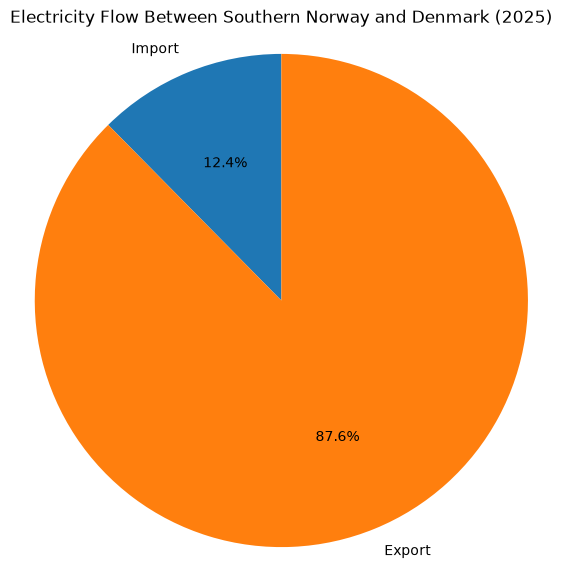

In [ ]:
# Converts the aggregated Spark data to pandas for plotting
pie_df = denmark_2025_df.toPandas()

# Creates a pie chart of import and export
plt.figure(figsize=(7, 7))

plt.pie(
    pie_df["total_mwh"],
    labels=pie_df["direction"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Electricity Flow Between Southern Norway and Denmark (2025)")
plt.axis("equal")
plt.show()

### Monthly Electricity Flows – Line Chart

In this section, I visualize electricity imports and exports
between Southern Norway (NO2) and Denmark (DK1) during January 2025.

In [ ]:

# Select electricity flows between Norway and Denmark in January 2025
january_flows_df = (
    flows_df
    .filter(
        (F.year("timestamp") == 2025)
        & (F.month("timestamp") == 1)
        & (
            ((F.col("out_area") == "NO2") & (F.col("in_area") == "DK1"))
            | ((F.col("out_area") == "DK1") & (F.col("in_area") == "NO2"))
        )
    )
    .groupBy(F.to_date("timestamp").alias("date"), "direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("date", "direction")
)

january_flows_df.show(10)

+----------+---------+------------------+
|      date|direction|         total_mwh|
+----------+---------+------------------+
|2025-01-01|   Export|               0.0|
|2025-01-01|   Import|        36785.2925|
|2025-01-02|   Export|          22774.34|
|2025-01-02|   Import| 6883.772499999999|
|2025-01-03|   Export|24484.360000000008|
|2025-01-03|   Import|               0.0|
|2025-01-04|   Export|38528.450000000004|
|2025-01-04|   Import|               0.0|
|2025-01-05|   Export|27439.070000000003|
|2025-01-05|   Import|             20.87|
+----------+---------+------------------+
only showing top 10 rows



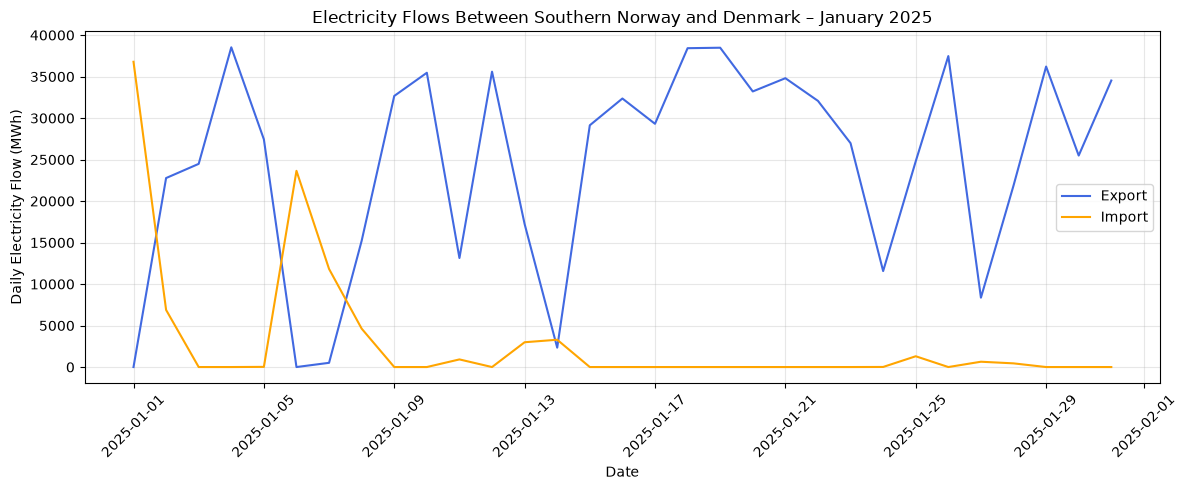

In [ ]:

# Convert the daily Spark results to pandas
january_pd = january_flows_df.toPandas()

# Put import and export in separate columns
january_plot = january_pd.pivot(
    index="date",
    columns="direction",
    values="total_mwh"
).fillna(0)

# Plot daily electricity flows
plt.figure(figsize=(12, 5))

plt.plot(
    january_plot.index,
    january_plot["Export"],
    label="Export",
    color="royalblue"
)

plt.plot(
    january_plot.index,
    january_plot["Import"],
    label="Import",
    color="orange"
)

plt.title("Electricity Flows Between Southern Norway and Denmark – January 2025")
plt.xlabel("Date")
plt.ylabel("Daily Electricity Flow (MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. MongoDB Integration

In this section, I transfer the data extracted from Cassandra using PySpark to MongoDB Atlas.

In [30]:
# Select the MongoDB database
db = client["ind320_project2"]

# Select the collection for electricity flows
collection = db["entsoe_flows"]

print("Database:", db.name)
print("Collection:", collection.name)

Database: ind320_project2
Collection: entsoe_flows


In [ ]:

# Aggregate electricity flows by date, connection and direction
daily_flows_df = (
    flows_df
    .withColumn("date", F.to_date("timestamp"))
    .groupBy("out_area", "in_area", "direction", "date")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("date")
)

# Check the aggregated data
daily_flows_df.show(10)

print("Number of daily records:", daily_flows_df.count())

+--------+-------+---------+----------+-----------------+
|out_area|in_area|direction|      date|        total_mwh|
+--------+-------+---------+----------+-----------------+
|     DK1|    NO2|   Import|2024-10-14|              0.0|
|     NO2|     GB|   Export|2024-10-14|              0.0|
|     SE2|    NO3|   Import|2024-10-14|        3316.7025|
|     NO1|    SE3|   Export|2024-10-14|           218.75|
|      GB|    NO2|   Import|2024-10-14|              0.0|
|     NO4|     FI|   Export|2024-10-14|           37.575|
|     NO2|    DK1|   Export|2024-10-14|          8321.56|
|     NO4|    SE1|   Export|2024-10-14|            399.9|
|     NO2|  DE-LU|   Export|2024-10-14|8205.919999999996|
|      NL|    NO2|   Import|2024-10-14|              0.0|
+--------+-------+---------+----------+-----------------+
only showing top 10 rows

Number of daily records: 13158


In [ ]:

# Select the collection for daily electricity flows
daily_collection = db["entsoe_daily_flows"]

# Prepare MongoDB operations
operations = []

for row in daily_flows_df.toLocalIterator():
    document = row.asDict()

    # Convert date to a MongoDB-compatible datetime
    document["date"] = datetime.combine(document["date"], time.min)

    # Identify each document by connection, direction and date
    filter_query = {
        "out_area": document["out_area"],
        "in_area": document["in_area"],
        "direction": document["direction"],
        "date": document["date"]
    }

    operations.append(
        ReplaceOne(filter_query, document, upsert=True)
    )

# Insert or update documents in MongoDB
if operations:
    daily_collection.bulk_write(operations, ordered=False)

print("Documents in MongoDB:", daily_collection.count_documents({}))

Documents in MongoDB: 13158
